# Pipeline & Deploy the Best Prediction Model

Based on the model comparison conducted in the **Bagging_Boosting_Model_2** analysis, the standard **XGBoost Regressor** showed the strongest overall performance for predicting a single property sale price. Therefore, this model was selected as the final model for pipeline development and **Streamlit** deployment.

**Streamlit** was used to deploy the final model as an interactive web application. Users can enter property, location, and market information through the interface, and the saved pipeline automatically preprocesses the inputs and produces an estimated sale price. The application was deployed through Streamlit Community Cloud using the model and application files stored in the GitHub repository.

We will use the same '**cleaned_data_eda.csv**' dataset and the same predictor features used in the previous **Bagging_Boosting_Model_2** analysis to maintain consistency between model training, evaluation, and deployment.

The previously selected XGBoost hyperparameters will be reused rather than performing hyperparameter tuning again. A pipeline will be constructed to combine the required data preprocessing steps with the final XGBoost model, allowing new property information to be processed and passed directly into the trained model for sale-price prediction.

# Imports

In [ ]:
# basic setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# train, test, validation sets
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

# pre-processing 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_transformer 
from sklearn.pipeline import Pipeline

# boosting model
from xgboost import XGBRegressor

# metrics score
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

In [ ]:
from sklearn import set_config

# display models and pipeline as plain text instead of HTML diagram
set_config(display="text")

# Data

Let's call back out **cleaned_data_eda.csv** dataset

In [3]:
# call csv dataset
df=pd.read_csv('cleaned_data_eda.csv')
print(df.shape)
df.head()

(47549, 31)


,ViewYN,PoolPrivateYN,ClosePrice,Latitude,Longitude,LivingArea,CountyOrParish,AttachedGarageYN,ParkingTotal,BathroomsTotalInteger,...,CPI,Age,LotDensity,FlooringType,SchoolDistrict,AgeGroup,CountyOrParish2,FlooringType2,SchoolCount2Miles,SchoolCountGroup
0,1,0,890000.0,34.180411,-118.342020,1434.0,Los Angeles,0,1,1.0,...,315.605,86.0,4.513947,Unknown,Burbank Unified,70+,Los Angeles,Unknown,21.0,20+ Schools
1,0,0,1138000.0,32.574359,-117.023836,2872.0,San Diego,1,6,3.0,...,315.605,25.0,1.817201,Unknown,Unknown,21-40,San Diego,Unknown,12.0,11-20 Schools
2,1,0,681877.0,33.725080,-117.222302,2824.0,Riverside,1,2,3.0,...,315.605,2.0,2.478754,Unknown,Unknown,0-5,Riverside,Unknown,2.0,1-5 Schools
3,1,0,900000.0,34.203479,-118.643567,2500.0,Los Angeles,1,2,3.0,...,315.605,55.0,3.334400,Unknown,Los Angeles Unified,41-70,Los Angeles,Unknown,12.0,11-20 Schools
4,0,0,862000.0,34.460368,-118.490755,2363.0,Los Angeles,1,2,3.0,...,315.605,31.0,4.953449,Unknown,Unknown,21-40,Los Angeles,Unknown,4.0,1-5 Schools


Let's check the data types and missing values in each feature.

In [4]:
df.dtypes

ViewYN                     int64
PoolPrivateYN              int64
ClosePrice               float64
Latitude                 float64
Longitude                float64
LivingArea               float64
CountyOrParish               str
AttachedGarageYN           int64
ParkingTotal               int64
BathroomsTotalInteger    float64
City                         str
BedroomsTotal            float64
FireplaceYN                int64
Stories                  float64
NewConstructionYN          int64
GarageSpaces             float64
LotSizeSquareFeet        float64
SalesTaxRate             float64
UnemploymentRate         float64
MortgageRate30Fixed      float64
FedInterestRate          float64
CPI                      float64
Age                      float64
LotDensity               float64
FlooringType                 str
SchoolDistrict               str
AgeGroup                     str
CountyOrParish2              str
FlooringType2                str
SchoolCount2Miles        float64
SchoolCoun

In [5]:
df.isna().sum()

ViewYN                   0
PoolPrivateYN            0
ClosePrice               0
Latitude                 0
Longitude                0
LivingArea               0
CountyOrParish           0
AttachedGarageYN         0
ParkingTotal             0
BathroomsTotalInteger    0
City                     0
BedroomsTotal            0
FireplaceYN              0
Stories                  0
NewConstructionYN        0
GarageSpaces             0
LotSizeSquareFeet        0
SalesTaxRate             0
UnemploymentRate         0
MortgageRate30Fixed      0
FedInterestRate          0
CPI                      0
Age                      0
LotDensity               0
FlooringType             0
SchoolDistrict           0
AgeGroup                 0
CountyOrParish2          0
FlooringType2            0
SchoolCount2Miles        0
SchoolCountGroup         0
dtype: int64

There is no missing values. We identified there is no implicit missing values as well that this dataset is cleaned from previous files. Now let's transform the categorical features with hot en-coding for computer to read categorical values. We will not use standard scaler at this point due to tree of boosting model of XGBoost Regressor that it does not requires standard scaler. 

In [6]:
continuous= [
    "Age",
    "CPI",
    "FedInterestRate",
    "Latitude",
    "LivingArea",
    "Longitude",
    "LotDensity",
    "LotSizeSquareFeet",
    "MortgageRate30Fixed",
    "SalesTaxRate",
    "UnemploymentRate"
]

discrete= [
    "BathroomsTotalInteger",
    "BedroomsTotal",
    "Stories",
    "GarageSpaces",
    "ParkingTotal",
    "SchoolCount2Miles"
]

categorical = [
    "CountyOrParish2",
    "FlooringType2",
    "AttachedGarageYN",
    "FireplaceYN",
    "NewConstructionYN",
    "PoolPrivateYN",
    "ViewYN"

]

# make feature pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            continuous + discrete
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
                drop="first"
            ),
            categorical
        )
    ]
)

Let's split the dataset for independent and dependent variables with spliting x and y training and test set.

In [7]:
# split features into independent and dependent variable
X = df.drop(columns = ["ClosePrice"])

y = df["ClosePrice"]

# construct training and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=48)

# Model

We had observed the best model with best hyper parameters on XGBoost Regressor from Bagging_Boosting_Model_2 file. We will use exact same parameters method using the pipeline process.

In [8]:
# create final model of xgboost regressor
model_xgb = XGBRegressor(
    
    objective="reg:squarederror",
    tree_method="hist",

    max_depth=11,
    min_child_weight=10,
    gamma=0,

    subsample=1,
    colsample_bytree=0.6,

    reg_alpha=0,
    reg_lambda=5,

    n_estimators = 500,
    learning_rate = 0.04,

    random_state=48,
    n_jobs=1
)


pipeline_model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", model_xgb)
    ]
)

pipeline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical', 'passthrough',
                                                  ['Age', 'CPI',
                                                   'FedInterestRate',
                                                   'Latitude', 'LivingArea',
                                                   'Longitude', 'LotDensity',
                                                   'LotSizeSquareFeet',
                                                   'MortgageRate30Fixed',
                                                   'SalesTaxRate',
                                                   'UnemploymentRate',
                                                   'BathroomsTotalInteger',
                                                   'BedroomsTotal', 'Stories',
                                                   'GarageSpaces',
                                                   'ParkingTotal',
                          

Let's test the result of this model.

In [ ]:
# predict close price from training and test set
pred_train2 = pipeline_model.predict(X_train)

pred_test2 = pipeline_model.predict(X_test)

# conduct median absolute percentage error
def median_absolute_percentage_error(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true))


# show the results of MAPE, MAE, RMSE, and R^2
print(f"MAPE: {mean_absolute_percentage_error(y_test, pred_test2) * 100} %")
print(f"MdAPE: {median_absolute_percentage_error(y_test, pred_test2) * 100} %")
print(f"RMSE: ${root_mean_squared_error(y_test, pred_test2)}")
print(f"MAE: ${mean_absolute_error(y_test, pred_test2)}")
print(f"R^2_test: {r2_score(y_test, pred_test2) * 100} %")
print(f"R^2_train: {r2_score(y_train, pred_train2) * 100} %")

MAPE: 11.611514031236894 %
MdAPE: 7.752534374222554 %
RMSE: $248277.23762744264
MAE: $130873.46535180074
R^2_test: 88.35522238868238 %
R^2_train: 98.01650745844546 %


- Test MAPE, predicted property prices differed from actual sale prices by approximately $11.61\%$ on average.

- Test MdAPE, the half of properties predicted sold price of the errors approximately $7.75\%$
 or less. This suggests that a typcial property was predicted within about $7.75\%$ of its actual sold price.

- Test MAE, predicted prices were off by approximately $\$130,873$ on average.

- Test RMSE is $\$248,277$ and it is higher than the MAE because it gives greater weight to large prediction errors. This difference suggests that some properties had large prediction errors.

- The model has test $R^2$, explaining approximately 88.57% of the variation in property prices amoong unseen observations.

- The gaps of $R^2$ between training $98\%$ and test $88\%$ is $10\%$ indicates small-mediate overfitting. However, the strong test performance suggests that final model still generalizes well to unseen properties.**

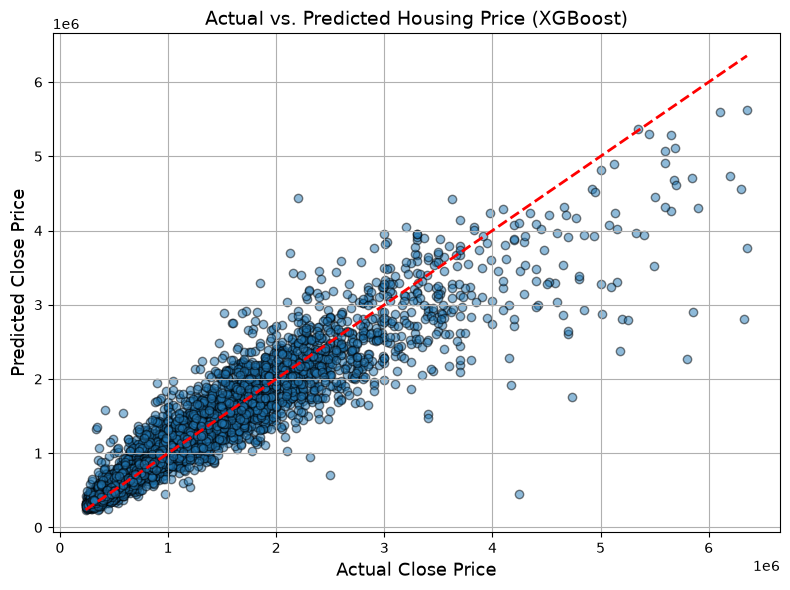

In [10]:
# show scatterplot for distribution actual vs. predicted price
plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred_test2, alpha=0.5, edgecolor='k')

# show the ideal red line for prediction
min_price = min(y_test.min(), pred_test2.min())
max_price = max(y_test.max(), pred_test2.max())


plt.plot([min_price, max_price],
         [min_price, max_price],
         color='red', linestyle='--', linewidth=2)

plt.title("Actual vs. Predicted Housing Price (XGBoost)", fontsize=14)
plt.xlabel("Actual Close Price", fontsize=13)
plt.ylabel("Predicted Close Price", fontsize=13)
plt.grid(True)
plt.tight_layout()
plt.show()


The most predicted values are close to the diagonal reference line, suggesting generally strong predictive performance. The low to mid property prices below $4 million clustered around the red line.

Above $4 million, the more actual price increase, the prediction of price tends to underpredict prices at upper end market falling down from red line. Serveral large errors are showing why RMSE is higher than MAE.

# Deploy Model

We will use **Joblib** library that used to save and reload trained machine learning models or pipelines saving to a file as '**model.pkl**'. 

Additionally, we will import **Streamlit** library to build the interactive web application. It is used to create the input fields and other application features that users can interact with in deployed model. 

**This process is the purpose to show the process of producing the deployed model into application. The other users are unecessary to follow this process, and here is the website where users can use the model directly without process.**

Deployed Model: https://californiarealestatedatascience-wct97ezpa4x4gpzaxcrale.streamlit.app/ 

Download the Streamlit in terminal "**pip install streamlit**".

In [ ]:
import joblib
import streamlit as st

# Save trained XGBoost model
joblib.dump(pipeline_model, 'model.pkl')
print("XGBoost model saved as 'model.pkl'")

XGBoost model saved as 'model.pkl'


We will make the file of Python prompt called '**app.py**' setting the application website of deploying the model. This prompt will be use in the Streamlit of community cloud website connecting to Github so that it operates application.

- Streamlit website: https://streamlit.io/cloud

- Github: https://github.com/junkuna/California_Real_Estate_Data_Science/tree/main 

This process is the purpose to show the process of producing the deployed model into application. The other users are unecessary to follow this process, 

In [ ]:
%%writefile app.py

# Load trained preprocessing + XGBoost pipeline
model = joblib.load("model.pkl")

# Get exact categories used during training
encoder = (
    model
    .named_steps["preprocessor"]
    .named_transformers_["categorical"]
)

categorical_columns = [
    "CountyOrParish2",
    "FlooringType2",
    "AttachedGarageYN",
    "FireplaceYN",
    "NewConstructionYN",
    "PoolPrivateYN",
    "ViewYN"
]

category_options = dict(
    zip(categorical_columns, encoder.categories_)
)

# set page configure
st.set_page_config(
    page_title="California Home Price Predictor",
    page_icon="🏠"
)

# set title
st.title("🏠 California Home Price Predictor")

# set information below title
st.write(
    "Enter the property and market information below "
    "to estimate the expected sale price."
)


# property information
st.subheader("Property Information")

living_area = st.number_input(
    "Living Area (sq ft)",
    min_value=0.0,
    value=1800.0
)

lot_size = st.number_input(
    "Lot Size (sq ft)",
    min_value=0.0,
    value=7000.0
)

age = st.number_input(
    "Property Age",
    min_value=0,
    value=30
)

bedrooms = st.number_input(
    "Bedrooms",
    min_value=0,
    value=3
)

bathrooms = st.number_input(
    "Bathrooms",
    min_value=0,
    value=2
)

stories = st.number_input(
    "Stories",
    min_value=0,
    value=1
)

garage_spaces = st.number_input(
    "Garage Spaces",
    min_value=0,
    value=2
)

parking_total = st.number_input(
    "Total Parking Spaces",
    min_value=0,
    value=2
)


# property location settting
st.subheader("Location")

latitude = st.number_input(
    "Latitude",
    value=34.0522,
    format="%.6f"
)

longitude = st.number_input(
    "Longitude",
    value=-118.2437,
    format="%.6f"
)

county = st.selectbox(
    "County",
    category_options["CountyOrParish2"]
)

school_count = st.number_input(
    "Public Schools Within 2 Miles",
    min_value=0,
    value=10
)


# additional property information setting
st.subheader("Additional Features")

flooring = st.selectbox(
    "Flooring Type",
    category_options["FlooringType2"]
)

attached_garage = st.selectbox(
    "Attached Garage",
    category_options["AttachedGarageYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

fireplace = st.selectbox(
    "Fireplace",
    category_options["FireplaceYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

new_construction = st.selectbox(
    "New Construction",
    category_options["NewConstructionYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

private_pool = st.selectbox(
    "Private Pool",
    category_options["PoolPrivateYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)

view = st.selectbox(
    "View",
    category_options["ViewYN"],
    format_func=lambda x: "Yes" if x == 1 else "No"
)


# setting real estate market condition settting
st.subheader("Market Conditions")

cpi = st.number_input(
    "CPI",
    value=320.0
)

fed_rate = st.number_input(
    "Federal Interest Rate",
    value=4.5
)

mortgage_rate = st.number_input(
    "30-Year Mortgage Rate",
    value=6.5
)

unemployment_rate = st.number_input(
    "Unemployment Rate",
    value=5.0
)

sales_tax_rate = st.number_input(
    "Sales Tax Rate",
    value=7.25
)

lot_density = st.number_input(
    "Lot Density",
    value=0.25
)


# model predict execution
if st.button("Predict Sale Price"):

    input_data = pd.DataFrame(
        [{
            "Age": age,
            "CPI": cpi,
            "FedInterestRate": fed_rate,
            "Latitude": latitude,
            "LivingArea": living_area,
            "Longitude": longitude,
            "LotDensity": lot_density,
            "LotSizeSquareFeet": lot_size,
            "MortgageRate30Fixed": mortgage_rate,
            "SalesTaxRate": sales_tax_rate,
            "UnemploymentRate": unemployment_rate,

            "BathroomsTotalInteger": bathrooms,
            "BedroomsTotal": bedrooms,
            "Stories": stories,
            "GarageSpaces": garage_spaces,
            "ParkingTotal": parking_total,
            "SchoolCount2Miles": school_count,

            "CountyOrParish2": county,
            "FlooringType2": flooring,
            "AttachedGarageYN": attached_garage,
            "FireplaceYN": fireplace,
            "NewConstructionYN": new_construction,
            "PoolPrivateYN": private_pool,
            "ViewYN": view
        }]
    )

    prediction = model.predict(input_data)[0]

    st.success(
        f"Estimated Sale Price: ${prediction:,.0f}"
    )

Writing app.py


Let's make requirement text prompt for the Streamlit application aligning which Python packages it must be installed to run the model. 

In [ ]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
xgboost
joblib